# This code is  for plotting the heatmaps of hysteresis to see the effect of having a constant inhibition, push-pull, ... because we want to replicate the effect of removing neuromodulation when the inhibition is increased

In [1]:
using Plots, Distributions, JLD, DSP, Parameters, Match, SymDict, NumericalIntegration, Random, MAT, Pkg, CSV, DataFrames, XLSX, Pkg, JLD2, Colors, JLD2,  Makie, CairoMakie, Optim, Serialization, JuMP, Ipopt, ForwardDiff, LinearAlgebra

include("functions_optim/creation_model_nofacilitation.jl")

┌ Warning: Error requiring `MakieCore` from `Polynomials`
│   exception = (LoadError("/Users/nmt121/.julia/packages/Polynomials/6i39P/ext/PolynomialsMakieCoreExt.jl", 1, ArgumentError("Package Polynomials does not have MakieCore in its dependencies:\n- If you have Polynomials checked out for development and have\n  added MakieCore as a dependency but haven't updated your primary\n  environment's manifest file, try `Pkg.resolve()`.\n- Otherwise you may need to report an issue with Polynomials")), Union{Ptr{Nothing}, Base.InterpreterIP}[Ptr{Nothing} @0x000000010abce4ae, Ptr{Nothing} @0x0000000108f499bf, Ptr{Nothing} @0x0000000108f7aa0c, Ptr{Nothing} @0x0000000108f79e62, Ptr{Nothing} @0x0000000108f79a65, Ptr{Nothing} @0x0000000108f7a104, Ptr{Nothing} @0x0000000108f7ac34, Ptr{Nothing} @0x000000011e11cd67, Ptr{Nothing} @0x0000000108f499bf, Ptr{Nothing} @0x000000011e00d28a, Ptr{Nothing} @0x000000011e00cd62, Ptr{Nothing} @0x0000000108f499bf, Ptr{Nothing} @0x0000000108f56259, Ptr{Nothing} @0x0

spikes_from_aps

In [2]:
function run_sim_inh(i,inh_input)
    full_input = commoninput 
    vd, vs, _ = ode4(tspan, 0.,0., i, pool_state_params[i], full_input,inh_input, MNs)  
    spikes = spikes_from_aps(vs, i, MNs)       
    spike_arr = reshape(spikes, 1, length(spikes))
    vs_arr[i,:] = vs
    return spike_arr, vs_arr
end

run_sim_inh (generic function with 1 method)

## Functions to use (to exclude faciliation effect because if not I have to define some inputs to the function)

In [3]:
using Parameters

"""
ODE_motoneuron
Computation of the state variables: ϕ̊ = α(1-ϕ) - βϕ
Computation of the soma and dendrite membrane potentials using the previous calculated stated variables, etc.
"""

function ODE_motoneuron(t::Float64, vd::Float64, vs::Float64,
    gc::Float64, gld::Float64, gls::Float64, gCa::Float64, Cd::Float64,
    Cs::Float64,  αp::Float64,  βp::Float64, VthCa::Float64, gNa::Float64,
    αm::Float64, βm::Float64, Vth::Float64, gKf::Float64, gKs::Float64, αh::Float64, βh::Float64,
    αn::Float64, βn::Float64, αq::Float64, βq::Float64, γh::Float64,IF::Float64, m::Float64, h::Float64, 
    n::Float64, q::Float64, p::Float64, m0::Float64, h0::Float64, n0::Float64, q0::Float64, p0::Float64,
    t0::Float64, t1::Float64, SPIKE0::Int64, SPIKE1::Int64, exc_input,inh_input)
    
    
    ### AP 
    if vs > Vth && (t0 == -1 || (t-t0) > rp)   #initiation of the AP
        SPIKE0 = 1; t0=t; m0=m; h0=h; n0=n;q0=q;#p0=p
    
    elseif SPIKE0 == 1 && (t-t0) > pd    #end of the AP
        SPIKE0 = 0; t0=t; m0=m; h0=h; n0=n; q0=q;#p0=p
    
    end
    
    if SPIKE0 > 0 #AP (forward equations)
    
        @fastmath m = 1+(m0-1) * exp(-αm*(t-t0)) 
        @fastmath h = h0*exp(-βh*(t-t0)) 
        @fastmath n = 1+(n0-1)*exp(-αn*(t-t0)) 
        @fastmath q = 1+(q0-1)*exp(-αq*(t-t0)) 
    
    else # (backward equations)
        @fastmath m = m0*exp(-βm*(t-t0))
        @fastmath h = 1+(h0-1)*exp(-αh*(t-t0))  
        @fastmath n = n0*exp(-βn*(t-t0))
        @fastmath q = q0*exp(-βq*(t-t0))
    
    end
    
    
    # ### CA CHANNELS 
    
    if vs > Vth && (t1 == -1 ) # Initiate Ca spike with AP
        SPIKE1 = 1
        t1 = t
        p0 = p
        
    elseif (vs > Vth - VthCa)  && (t1 != -1) && (t - t1) > rp    
        SPIKE1 = 1
        t1 = t
        p0 = p
    
    elseif SPIKE1 == 1 && (t - t1) > pd
        SPIKE1 = 0
        t1 = t  
        p0 = p
    
    
    end
    
    
    if SPIKE1 > 0
        @fastmath p = 1 + (p0 - 1) * exp(-αp * (t - t1))
    else
        @fastmath p = p0 * exp(-βp * (t - t1))
    end
    
    
    
    @fastmath new_vs = (1/Cs)*(-gc*(vs-vd)-gls*(vs-EL)-gNa*m^3*h*(vs-ENa)-gKf*n^4*(vs-EK)-gKs*q^2*(vs-EK))
    
    @fastmath new_vd = (1/Cd)*(-gc*(vd-vs)-gld*(vd-EL)-γh*gCa*p*(vd-ECa)-exc_input*Ge*(vd-Ee)- IF*inh_input*Gi*(vd-Ei))
    
    return new_vd, new_vs, m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1

end
    
    
    

"""
ode4(tspan, vd0, vs0, MN_i, state_params, exc_input,inh_input)
Computes voltage values for the soma and the dendrite for each time step
"""
function ode4(tspan, vd0, vs0, MN_i, state_params, exc_input,inh_input, MNs)
# unpack the variables that are in the MN list for one specififc motoneuron i

@unpack gc, gld, gls, gCa, Cd, Cs,  αp, βp, VthCa, gNa, αm, βm, Vth, gKf, gKs, αh, βh, αn, βn,
αq, βq, γh,IF= stringdict(MNs[MN_i])  

# state parameters

m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1 = state_params

N = length(tspan)-1 #number of steps
Vd = zeros(N) 
Vs = zeros(N)
Pt=zeros(N)
Mt=zeros(N)
Ht=zeros(N)
Nt=zeros(N)
Qt=zeros(N)

Vd[1] = vd0
Vs[1] = vs0
Pt[1] = p0
Mt[1] = m0
Ht[1] = h0
Nt[1] = n0
Qt[1] = q0


e_inp_prev=0
for i in 2:N #computation for time step
    ti = tspan[i-1] #previous time point
    hi = 0.05 #step size por integration, how far we look again in each interval
    vd = Vd[i-1] #voltage dendrite-value for the previous time step
    vs = Vs[i-1] #voltage soma-value for the previous time step
    e_inp = exc_input[_int(ti+1)] 
    i_inp = inh_input[_int(ti+1)]
    


    #Fourth-order Runge-Kutta method that solves differential equations with step-size of 0.05ms.

    vd1, vs1, m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1 = ODE_motoneuron(ti, vd, vs, gc,
    gld, gls, gCa, Cd, Cs, αp,  βp, VthCa, gNa, αm, βm, Vth, gKf, gKs, αh, βh, αn, βn,
    αq, βq,γh, IF, m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1, e_inp,i_inp)

    vd2, vs2, m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1 = ODE_motoneuron(ti+0.5*hi,
    vd+0.5*hi*vd1, vs+0.5*hi*vs1, gc, gld, gls, gCa, Cd, Cs,  αp,  βp, VthCa, gNa, αm, βm, Vth, gKf,
    gKs, αh, βh, αn, βn, αq, βq, γh, IF, m, h , n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1, e_inp,i_inp)

    vd3, vs3, m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1 = ODE_motoneuron(ti+0.5*hi,
    vd+0.5*hi*vd2, vs+0.5*hi*vs2, gc, gld, gls, gCa, Cd, Cs,  αp,  βp, VthCa, gNa, αm, βm, Vth, gKf,
    gKs, αh, βh, αn, βn, αq, βq, γh, IF, m,h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1, e_inp,i_inp)

    vd4, vs4, m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1 = ODE_motoneuron(tspan[i],
    vd+hi*vd3, vs+hi*vs3, gc, gld, gls, gCa, Cd, Cs,  αp,  βp, VthCa, gNa, αm, βm, Vth, gKf,
    gKs, αh, βh, αn, βn, αq, βq, γh, IF, m,h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1, e_inp,i_inp)

    #to compute voltage for the next step
    Vd[i] = vd + (hi/6)*(vd1+2*vd2+2*vd3+vd4) #vd1 and vd4 are given a weight of 1 and vd2 and vd3 a weight of 2 because they are more reliable
    Vs[i] = vs + (hi/6)*(vs1+2*vs2+2*vs3+vs4)
    Pt[i] = p
    Mt[i] = m
    Ht[i] = h
    Nt[i] = n
    Qt[i] = q

    e_inp_prev= e_inp


end
state_params = (m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1)
return Vd, Vs, state_params,Pt, Mt, Ht, Nt, Qt
end


"""
spikes_from_aps(time_series, i) 
Returns spikes from the soma based on wheter the neuron voltage exceeds a specific threshold at a given time point (voltage t > threshold???)
* voltage_time_series = soma voltage returned by 'ode4' function (see function that runs simulation)
"""
function spikes_from_aps(voltage_time_series, i, MNs)
spikes = zeros(Int64, length(voltage_time_series))
for t = 2:length(voltage_time_series)-1
    # check if voltage is bigger than threshold (Vth)
    # Generate 1 or 0 from Boolean dependending on whether the element meets both conditions
    cond1 = voltage_time_series[t] > MNs[i][:Vth]
    cond2 = voltage_time_series[t-1] < voltage_time_series[t] > voltage_time_series[t+1]
    spikes[t]= _int(cond1 && cond2)
end
return spikes
end



spikes_from_aps

In [4]:
######################  S-TYPE ##########################
#########################################################
nr_s = 10
# JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/hystprofile_NEW.jld2" γn_new
# JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/VthCa_new.jld2" VthCa_new


# Radius and soma lengths
rheobase_S = LinRange(3.5,6.5,nr_s) .+ rand(Normal(0.0,0.05),nr_s)  
rs_S = LinRange(38.75,41.25,nr_s)./10000 
ls_S = LinRange(77.5,82.5,nr_s)./10000 
rms_S = LinRange(1.15, 1.05,nr_s).*1000
rd_S = LinRange(20.75,31.25,nr_s)./10000 
ld_S = LinRange(5500.,6800.,nr_s)./10000 
rmd_S = LinRange(14.4,10.70,nr_s).*1000 

#  Maximun conductances for each of the ION channels mS/cm^2 
max_gna = 30.0 
max_gkf_S = ones(nr_s)*4 
max_gks_S =LinRange(16,25,nr_s) 
max_gca_S = LinRange(0.038,0.029,nr_s) 


# Rate constants of the kinetic processes in ms^-1
αm = ones(nr_s)*22.0
βm = ones(nr_s)*13.0

αh_S = ones(nr_s)*0.5
βh_S = ones(nr_s)*4

αn_S = ones(nr_s)*1.5
βn_S = ones(nr_s)*0.1

αq_S = ones(nr_s)*1.5
βq_S = LinRange(0.025,0.038,nr_s) 

αp_D = 0.008
βp_D = LinRange(0.014,0.016,nr_s) 


Apeak_S = LinRange(0.103,0.123,nr_s)
tpeak_S = LinRange(110.,100.,nr_s) 
tetanic_S = LinRange(0.393,0.491,nr_s);


#EXCITATORY PROFILE
amplitude=0.4
tr_length=28000
half_triang = div(tr_length, 2)  
flat_line = fill(-0.1, 1000)
up = range(-0.1, amplitude, length = half_triang + 1)  
down = range(amplitude, -0.1, length = tr_length - half_triang + 1)  
tr = vcat(flat_line, up[2:end], down[2:end], flat_line)
sim_length=30000

# at some point delete these things
γa=1.;
γh = ones(nr_s)#γn_new
IF= LinRange(1.,1.,nr_s);  #factor for the inhibtion

#reversal potentials
EL=0; ENa=120; ECa=140; EK=-10; Ee=70; Ei=-16 

#maximun conductances
Ge=0.6; Gi=0.5 ; 

#initial voltages
Vd0 = 0.; 
Vs0 = 0.;

#refractory period
rp=5.0; 

const step = 0.05;
_int(num) = floor(Int, num);

#Pulse duration [mS]
pd=1; 

ri = 70.  # Ω.cm 3intracellular resistivity
cm = 1.; #membrane capacitance

Vthca_S= ones(nr_s);

MN_list=[];
Vth_S = zeros(nr_s); gls_S = zeros(nr_s); gld_S = zeros(nr_s); gc_S = zeros(nr_s); gna_S = zeros(nr_s); gkf_S = zeros(nr_s); gks_S = zeros(nr_s); gca_S = zeros(nr_s); rn_S = zeros(nr_s); cs_S = zeros(nr_s)  ; cd_S = zeros(nr_s)
for i in 1:nr_s 
    ##assuming that the somatic membrane can be modeled as a cylinder and using the defined parameters from the previous section
    gls_S[i] = ((2*π*rs_S[i]*ls_S[i])/rms_S[i])*1e6  # conductance of the soma for the ith neuron (uS)
    gld_S[i] = ((2*π*rd_S[i]*ld_S[i])/rmd_S[i])*1e6  # # conductance of the dendrite for the ith neuron (uS)
    gc_S[i] = ((2/(((ri*ld_S[i])/(π*rd_S[i]^2))+((ri*ls_S[i])/(π*rs_S[i]^2)))))*1e6    # coupling conductance in uS
    rn_S[i] = 1/(gls_S[i]+((gld_S[i]*gc_S[i])/(gld_S[i]+gc_S[i]))) # input resistance of the neuron in MΩ     
    Vth_S[i] = round(rn_S[i]*rheobase_S[i],digits=2)   # in mV
    cs_S[i] = 2*π*ls_S[i]*rs_S[i]*cm*1e3   #inner capacitance of the soma nF
    cd_S[i] = 2*π*ld_S[i]*rd_S[i]*cm*1e3   #nF
    
    #conductances uS:
    gna_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gna*1e3          
    gkf_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gkf_S[i]*1e3     
    gks_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gks_S[i]*1e3     
    gca_S[i] = 2*π*ld_S[i]*rd_S[i]*max_gca_S[i]*1e3     

    S_MN = Dict(:Cs => cs_S[i], :Cd => cd_S[i], :Irh => rheobase_S[i], :gc => gc_S[i], :gNa => gna_S[i], :gKs => gks_S[i], :gKf => gkf_S[i], :gCa => gca_S[i], :gld => gld_S[i], :gls => gls_S[i], :αp => αp_D, :βp => βp_D[i], 
        :αq => αq_S[i], :βq => βq_S[i], :αm => αm[i], :βm => βm[i], :αh => αh_S[i], :βh => βh_S[i], :αn => αn_S[i], :βn => βn_S[i], :Vth => Vth_S[i], :VthCa => Vthca_S[i], :Rn => rn_S[i],
        :Tetanic => tetanic_S[i], :Apeak => Apeak_S[i],:IF => IF[i], :tpeak => tpeak_S[i], :γh=>γh[i] , "type" => "All Type")
 
    MN_list = [MN_list;S_MN];
end
MNs = MN_list;


tspan = 0:0.05:sim_length; #time span of simulation defined by step size and length of simulation // change this to get more or less points in the simulation
m=0.0;h=1.0;n=0.0;q=0.0;p=0.0;m0=0.0;h0=1.0;n0=0.0;q0=0.0;p0=0.0; t0=-1.0; t1=-1.0; SPIKE0=0; SPIKE1=0
pool_state_params = fill((m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1), nr_s) 
sim_time = _int(sim_length/0.05)   # because the step size is 0.05ms
spike_arr = zeros((nr_s, sim_time)) #storage
vs_arr = zeros((nr_s, sim_time)); #storage
pt_arr = zeros((nr_s, sim_time)); #storage
mt_arr = zeros((nr_s, sim_time)); #storage
ht_arr = zeros((nr_s, sim_time)); #storage
nt_arr = zeros((nr_s, sim_time)); #storage
qt_arr = zeros((nr_s, sim_time)); #storage
commoninput = tr; #needed for the run_sim() function


full_input = zeros((nr_s, sim_length))
independantnoise = zeros((nr_s, sim_length))
factor= 0.1 #for creating the inhibitory signal
inh_input=fill(factor*amplitude, sim_length);


In [40]:
#########################################################################################
################## CHANGING VALUES OF NEUROMOD AND CONSTANT INHIBITION ##################
#########################################################################################

vector_vthca=  LinRange(0,10,10)   
vector_inh=  LinRange(0.,1.,10)
hysteresis_for_each_inh= zeros(10,10)
n=2

for j in 1:length(vector_vthca)
    for k in 1:length(vector_inh)
        
        vthca= vector_vthca[j] 
        factor= vector_inh[k]        
        inh_input=fill(factor*amplitude, sim_length)
     

        MN_list[n][:VthCa] = vthca

        MNs= MN_list

        
        spike_array, vs_array = run_sim_inh(n, inh_input);


        amplitude=0.4;
        sim_length=560000 ;
        half_triang = div(sim_length, 2);  
        flat_line = fill(-0.1, 20000);
        up = range(-0.1, amplitude, length = half_triang + 1)  ;
        down = range(amplitude, -0.1, length = sim_length - half_triang + 1);  
        tr = vcat(flat_line, up[2:end], down[2:end], flat_line);

        
        
        if any(spike_array[1, :] .== 1)
            
            value_1= tr[findfirst(==(1),spike_array[1,:]),:] #force at the recruitment threshold
            value_2=  tr[findlast(==(1),spike_array[1,:]),:] #force at the derecruitment threshold

            hysteresis_for_each_inh[j,k]= ((value_2/value_1).-1)[1]
        else
            hysteresis_for_each_inh[j,k]=100
        end

    end

end


In [36]:
################################################################################
################## CHANGING VALUES OF NEUROMOD AND INHIBITION ##################
################################################################################

vector_vthca=  LinRange(0,10,10)   
vector_inh=  LinRange(0.,1.,10)
hysteresis_for_each_inh= zeros(10,10)
n=2


for j in 1:10
    for k in 1:10
        
        vthca= vector_vthca[j] 

        factor= vector_inh[k]        
        
        MN_list[n][:VthCa] = vthca

        MNs= MN_list

        # #inverse
        # amplitude=0.4*factor
        # tr_length=28000
        # half_triang = div(tr_length, 2)  
        # flat_line = fill(-0.1, 1000)
        # up = range(-0.1, amplitude, length = half_triang + 1)  
        # down = range(amplitude, -0.1, length = tr_length - half_triang + 1)  
        # inh_input = vcat(flat_line, up[2:end], down[2:end], flat_line)

        # balanced
        amplitude=0.4
        a=0.4*factor
        tr_length=30000
        half_triang = div(tr_length, 2)  
        down = range(amplitude, -0.1+a, length = half_triang + 1)  
        up = range(-0.1+a, amplitude, length = tr_length - half_triang + 1)  
        inh_input = vcat(down[2:end], up[2:end])

        
        spike_array, vs_array = run_sim_inh(n, inh_input);


        amplitude=0.4;
        sim_length=560000 ;
        half_triang = div(sim_length, 2);  
        flat_line = fill(-0.1, 20000);
        up = range(-0.1, amplitude, length = half_triang + 1)  ;
        down = range(amplitude, -0.1, length = sim_length - half_triang + 1);  
        tr = vcat(flat_line, up[2:end], down[2:end], flat_line);

        if any(spike_array[1, :] .== 1)
            
            value_1= tr[findfirst(==(1),spike_array[1,:]),:] #force at the recruitment threshold
            value_2=  tr[findlast(==(1),spike_array[1,:]),:] #force at the derecruitment threshold

            hysteresis_for_each_inh[j,k]= ((value_2/value_1).-1)[1]
        else
            hysteresis_for_each_inh[j,k]=100
        end

    end

end


In [42]:
JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap2_constant_gamma1.jld2" hysteresis_for_each_inh


In [9]:
hysteresis_for_each_inh[1,:]

10-element Vector{Float64}:
 0.009380079362917515
 0.02220627865467395
 0.012532764709352717
 0.0018748478207937236
 0.015868427220876447
 0.0067891674059816776
 0.018094246290028648
 0.009400705052879044
 0.018816485807451766
 0.010371406750399492

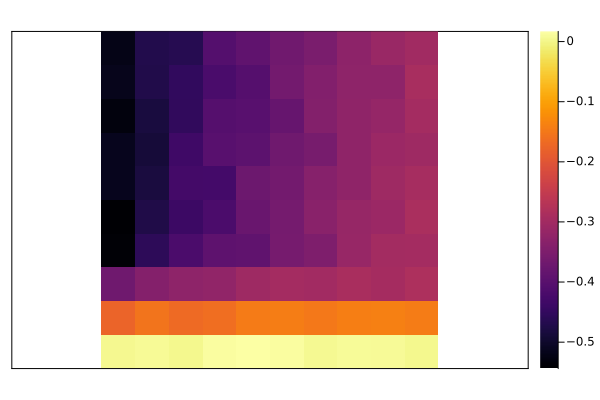

In [41]:

hysteresis_for_each_inh_modified = copy(hysteresis_for_each_inh)  
hysteresis_for_each_inh_modified[hysteresis_for_each_inh .> 99] .= NaN

Plots.heatmap(hysteresis_for_each_inh_modified,color=:inferno, aspect_ratio=1, grid=false, xticks=false, yticks=false, xlabel="", ylabel="", frame=:box)              
